# LSTM config d, retrained on raw (not log) wind speed -- standalone

**Config**: identical to config d -- LSTM 128/64, dropout 0.2, dense 16, lr 0.001, batch 128. The only thing that changed is the data: retrained directly on the current raw `Wind_Speed_10m_m_s` feature (config d's original scaler was fit on a log-transformed variant of that column).

Everything else (data loading, split, scaling, windowing, architecture, training, validation/test/rolling-origin evaluation, summary.json) is identical in structure to `model_training_LSTM_multistep_sweep.ipynb`, the parameterized sweep template this was generated from.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from numpy.lib.stride_tricks import sliding_window_view
import tensorflow as tf
from tensorflow import keras
import joblib
import time

tf.random.set_seed(42)
np.random.seed(42)

# make GPU training reproducible: cuDNN's fused LSTM kernel is NOT
# deterministic by default (its reductions run in whatever order GPU
# threads finish in), so np/tf seeds alone don't guarantee the same
# result across reruns -- this forces deterministic (slower) kernels
tf.config.experimental.enable_op_determinism()

# let TF grow VRAM on demand instead of reserving it all upfront
for _gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(_gpu, True)


I0000 00:00:1788337217.716824  228543 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788337217.754613  228543 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788337218.572583  228543 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Run configuration

Hardcoded below (not read from env vars) -- this is a standalone, single-purpose retrain, not part of the `run_sweep.sh` driver.

In [2]:
RUN_NAME = 'd_raw'
LSTM1_UNITS = 128
LSTM2_UNITS = 64
DROPOUT_RATE = 0.2
DENSE_UNITS = 16
LEARNING_RATE = 1e-3
BATCH_SIZE = 128
RECURRENT_DROPOUT_RATE = 0.0

print(f'Run "{RUN_NAME}": LSTM {LSTM1_UNITS}/{LSTM2_UNITS}  dropout {DROPOUT_RATE}  '
      f'dense {DENSE_UNITS}  lr {LEARNING_RATE}  batch {BATCH_SIZE}  '
      f'recurrent_dropout {RECURRENT_DROPOUT_RATE}')

Run "d_raw": LSTM 128/64  dropout 0.2  dense 16  lr 0.001  batch 128  recurrent_dropout 0.0


## 1. Load data + feature-selected feature set

Same feature set as the 1-hour base model (Run 4/8's 14 features), so any
difference between the two notebooks' results is attributable to the
direct-vs-recursive multi-step architecture, not to feature choice.

In [3]:
DATA_PATH = '../../../data/FYP_Cleaned_Dataset.csv'

df = pd.read_csv(DATA_PATH, parse_dates=['Datetime'])
df = df.sort_values(['State', 'Datetime']).reset_index(drop=True)

# lag features, per state, before the split (real deployment always has recent
# real GHI available before predicting the next step -> not leakage)
df['GHI_lag_1h'] = df.groupby('State')['GHI_W_m2'].shift(1)
df['GHI_lag_24h'] = df.groupby('State')['GHI_W_m2'].shift(24)
df = df.dropna(subset=['GHI_lag_1h', 'GHI_lag_24h']).reset_index(drop=True)

# best-known feature set (feature_selection.ipynb + Run 4/8): drop
# Surface_Pressure_kPa, Longitude, Temp_Air_2m_C; add the two GHI lags
FEATURE_COLS = [
    'Latitude', 'Cloud_Coverage_Pct', 'Temp_Skin_C',
    'Relative_Humidity_Pct', 'Wind_Speed_10m_m_s',
    'Precipitable_Water_cm', 'Rainfall_mm_log', 'Is_Daylight',
    'Hour_sin', 'Hour_cos', 'Wind_Sine', 'Wind_Cosine',
    'GHI_lag_1h', 'GHI_lag_24h',
]
TARGET_COL = 'GHI_W_m2'

print(df.shape)
df.head()


(1314000, 20)


,Datetime,State,Latitude,Longitude,GHI_W_m2,Cloud_Coverage_Pct,Temp_Skin_C,Relative_Humidity_Pct,Wind_Speed_10m_m_s,Wind_Direction_10m_deg,Precipitable_Water_cm,Hour,Is_Daylight,Hour_sin,Hour_cos,Wind_Sine,Wind_Cosine,Rainfall_mm_log,GHI_lag_1h,GHI_lag_24h
0,2016-01-03 00:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.83,25.63,94.90,2.74,3.1,5.71,0,0,0.000000,1.000000,0.054079,0.998537,3.442979,0.0,0.0
1,2016-01-03 01:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,100.00,25.54,95.00,2.68,1.7,5.74,1,0,0.258819,0.965926,0.029666,0.999560,3.337192,0.0,0.0
2,2016-01-03 02:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.72,25.47,94.96,2.62,358.9,5.68,2,0,0.500000,0.866025,-0.019197,0.999816,3.377929,0.0,0.0
3,2016-01-03 03:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.68,25.42,94.93,2.60,354.9,5.68,3,0,0.707107,0.707107,-0.088894,0.996041,3.371425,0.0,0.0
4,2016-01-03 04:00:00,Johor (Johor Bahru),1.4927,103.7414,0.0,99.98,25.39,94.82,2.65,350.2,5.67,4,0,0.866025,0.500000,-0.170209,0.985408,3.349904,0.0,0.0


## 2. Chronological train/val/test split (per state, 70/10/20)

Identical split logic to the base notebook, so train/val/test periods line up
exactly between the two.

In [4]:
TRAIN_FRAC = 0.7
VAL_FRAC = 0.1

def split_state(group):
    n = len(group)
    train_end = int(n * TRAIN_FRAC)
    val_end = int(n * (TRAIN_FRAC + VAL_FRAC))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_parts, val_parts, test_parts = [], [], []
for state, group in df.groupby('State', sort=False):
    tr, va, te = split_state(group)
    train_parts.append(tr); val_parts.append(va); test_parts.append(te)

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print('Train:', train_df.shape, train_df['Datetime'].min(), '-', train_df['Datetime'].max())
print('Val:  ', val_df.shape, val_df['Datetime'].min(), '-', val_df['Datetime'].max())
print('Test: ', test_df.shape, test_df['Datetime'].min(), '-', test_df['Datetime'].max())


Train: (919785, 20) 2016-01-03 00:00:00 - 2022-12-31 22:00:00
Val:   (131415, 20) 2022-12-31 23:00:00 - 2023-12-31 23:00:00
Test:  (262800, 20) 2024-01-01 00:00:00 - 2025-12-30 23:00:00


## 3. Scale (fit on train only)

In [5]:
x_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaler = MinMaxScaler(feature_range=(0, 1))

x_scaler.fit(train_df[FEATURE_COLS])
y_scaler.fit(train_df[[TARGET_COL]])

def scale(frame):
    frame = frame.copy()
    frame[FEATURE_COLS] = x_scaler.transform(frame[FEATURE_COLS])
    frame[TARGET_COL + '_scaled'] = y_scaler.transform(frame[[TARGET_COL]])
    return frame

train_scaled = scale(train_df)
val_scaled = scale(val_df)
test_scaled = scale(test_df)


## 4. Windowed sequences — direct 24-in / 24-out (per state, then combined)

Each training example is now `(24h of D's features) -> (24h of D+1's GHI)`,
built with a stride-1 sliding window across each state's timeline (every hour
offset, not just midnight starts) to maximize training signal — the model
already knows time-of-day from `Hour_sin`/`Hour_cos`/`Is_Daylight`, so it
doesn't need every training window to start at midnight to learn correctly.
The **midnight-anchored, calendar-day** version — matching the actual product
usage ("real day D -> predict entire D+1") — is what section 9's rolling-origin
backtest uses.

To keep the two arrays (`X` windows of length 24, `y` windows of length 24)
aligned without ever materializing one full windowed copy in memory, both are
built with `keras.utils.timeseries_dataset_from_array` off *offset* views of
the same underlying per-state array (`X` truncated by 24 at the end, `y`
truncated by 24 at the start) — same window count, same window order, so
zipping them pairs each `D` window with its own `D+1` target correctly.

In [6]:
WINDOW_SIZE = 24
OUTPUT_HORIZON = 24  # direct multi-step: predict the whole next day at once
# BATCH_SIZE comes from the run-configuration cell above

def build_multistep_dataset(frame, shuffle, stride=1):
    datasets = []
    for _, group in frame.groupby('State', sort=False):
        group = group.sort_values('Datetime')
        n = len(group)
        if n <= WINDOW_SIZE + OUTPUT_HORIZON:
            continue
        X = group[FEATURE_COLS].to_numpy(dtype='float32')
        y = group[TARGET_COL + '_scaled'].to_numpy(dtype='float32')

        # offset views so identical windowing on both arrays yields aligned
        # (D window) <-> (D+1 target window) pairs -- see markdown above
        X_for_windowing = X[: n - OUTPUT_HORIZON]
        y_for_windowing = y[WINDOW_SIZE:]

        ds_X = keras.utils.timeseries_dataset_from_array(
            data=X_for_windowing, targets=None, sequence_length=WINDOW_SIZE,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        ds_y = keras.utils.timeseries_dataset_from_array(
            data=y_for_windowing, targets=None, sequence_length=OUTPUT_HORIZON,
            sequence_stride=stride, batch_size=BATCH_SIZE,
        )
        datasets.append(tf.data.Dataset.zip((ds_X, ds_y)))

    combined = datasets[0]
    for ds in datasets[1:]:
        combined = combined.concatenate(ds)
    if shuffle:
        combined = combined.shuffle(buffer_size=10_000, seed=42)
    return combined.prefetch(tf.data.AUTOTUNE)

train_ds = build_multistep_dataset(train_scaled, shuffle=True, stride=1)
val_ds = build_multistep_dataset(val_scaled, shuffle=False, stride=1)
test_ds = build_multistep_dataset(test_scaled, shuffle=False, stride=1)

for xb, yb in train_ds.take(1):
    print('Batch X shape:', xb.shape, 'Batch y shape:', yb.shape)


I0000 00:00:1788337221.321421  228543 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1788337233.855209  228746 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 3391 of 10000


Batch X shape: (128, 24, 14) Batch y shape: (128, 24)


I0000 00:00:1788337249.075784  228746 shuffle_dataset_op.cc:483] Shuffle buffer filled.


## 5. Model — LSTM (configurable), direct `Dense(24)` output

Same backbone shape as the 1-hour base model (2 LSTM layers -> dropout ->
`Dense(..., relu)`); the actual widths/dropout/LR come from the run
-configuration cell (section 0) so the same notebook drives the whole
hyperparameter sweep. Only the output layer is fixed at `Dense(24)` so the
network always emits the whole next day in one shot instead of one hour.


In [7]:
n_features = len(FEATURE_COLS)

model = keras.Sequential([
    keras.layers.Input(shape=(WINDOW_SIZE, n_features)),
    keras.layers.LSTM(LSTM1_UNITS, return_sequences=True, recurrent_dropout=RECURRENT_DROPOUT_RATE),
    keras.layers.Dropout(DROPOUT_RATE),
    keras.layers.LSTM(LSTM2_UNITS, recurrent_dropout=RECURRENT_DROPOUT_RATE),
    keras.layers.Dropout(DROPOUT_RATE),
    keras.layers.Dense(DENSE_UNITS, activation='relu'),
    keras.layers.Dense(OUTPUT_HORIZON),  # direct 24h-ahead output, no recursion
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss='mse', metrics=['mae'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 128)        │        73,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,072 (484.66 KB)

 Trainable params: 124,072 (484.66 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
]

train_start = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
train_duration_sec = time.time() - train_start

best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f'Training time: {train_duration_sec/60:.2f} min, best epoch {best_epoch}/{len(history.history["val_loss"])}')


Epoch 1/50


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


I0000 00:00:1788337260.682375  228823 shuffle_dataset_op.cc:453] ShuffleDatasetV3:359: Filling up shuffle buffer (this may take a while): 2504 of 10000


I0000 00:00:1788337279.593724  228823 shuffle_dataset_op.cc:483] Shuffle buffer filled.
I0000 00:00:1788337279.599031  228665 cuda_dnn.cc:461] Loaded cuDNN version 92400


   1/7185 ━━━━━━━━━━━━━━━━━━━━ 61:29:58 31s/step - loss: 0.1788 - mae: 0.2832

   4/7185 ━━━━━━━━━━━━━━━━━━━━ 2:49 24ms/step - loss: 0.1206 - mae: 0.2321   

... (30,627 outputs left out)

7178/7185 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0040 - mae: 0.0342

7183/7185 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0040 - mae: 0.0342

7185/7185 ━━━━━━━━━━━━━━━━━━━━ 116s 12ms/step - loss: 0.0040 - mae: 0.0342 - val_loss: 0.0040 - val_mae: 0.0334 - learning_rate: 3.1250e-05


Training time: 41.71 min, best epoch 17/22


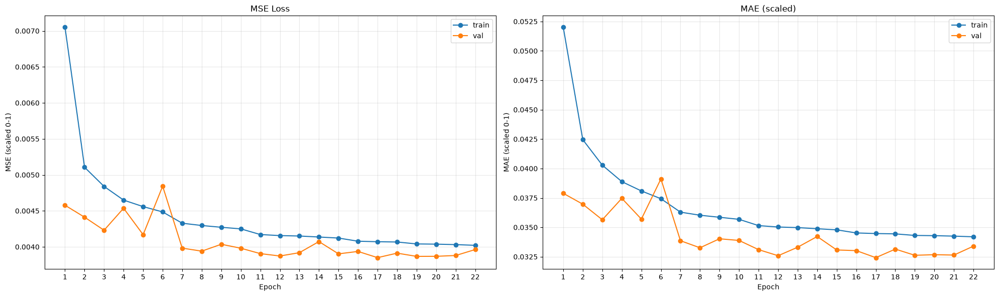

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

epochs = range(1, len(history.history['loss']) + 1)

axes[0].plot(epochs, history.history['loss'], label='train', marker='o')
axes[0].plot(epochs, history.history['val_loss'], label='val', marker='o')
axes[0].set_title('MSE Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE (scaled 0-1)')
axes[0].set_xticks(list(epochs))
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, history.history['mae'], label='train', marker='o')
axes[1].plot(epochs, history.history['val_mae'], label='val', marker='o')
axes[1].set_title('MAE (scaled)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE (scaled 0-1)')
axes[1].set_xticks(list(epochs))
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## 6b. Validation evaluation — the metric that picks the sweep winner

**Why this section exists, and why it's separate from section 7 below:**
comparing sweep configs (A/B1/B2/C/D/E) by their *test* metrics would mean
the test set was used to make a modeling decision (which config to pick) --
at that point it's no longer a valid held-out estimate of how the chosen
model generalizes. The validation split was never touched by any of that
decision-making, so it's what the sweep must be judged on.

**Selection rule:** across the sweep, compare `validation_pooled` --
primarily RMSE, with MAE/R² as supporting evidence -- to choose the winning
config. Only after that choice is locked in should section 7's test numbers
(or section 9's rolling-origin numbers) be looked at, and only for the
winning config -- they're recorded for every config here for research
completeness, not to be used for picking a winner.

In [10]:
y_true_val_scaled = np.concatenate([y.numpy() for _, y in val_ds], axis=0)  # (n, 24)
y_pred_val_scaled = model.predict(val_ds)  # (n, 24)

y_true_val = y_scaler.inverse_transform(y_true_val_scaled.reshape(-1, 1)).reshape(y_true_val_scaled.shape)
y_pred_val = y_scaler.inverse_transform(y_pred_val_scaled.reshape(-1, 1)).reshape(y_pred_val_scaled.shape)
y_pred_val = np.clip(y_pred_val, 0, None)

val_mae = mean_absolute_error(y_true_val.flatten(), y_pred_val.flatten())
val_rmse = np.sqrt(mean_squared_error(y_true_val.flatten(), y_pred_val.flatten()))
val_r2 = r2_score(y_true_val.flatten(), y_pred_val.flatten())
val_mbe = float(np.mean(y_pred_val.flatten() - y_true_val.flatten()))
val_nrmse = float(val_rmse / np.mean(y_true_val.flatten()) * 100)
print(f'Validation (all origins, all horizons pooled) MAE: {val_mae:.4f}  RMSE: {val_rmse:.4f}  '
      f'R2: {val_r2:.4f}  MBE: {val_mbe:.4f}  nRMSE: {val_nrmse:.2f}%  (W/m²)')
print('^ this is the number that should decide the sweep winner, not the test metrics below.')

   1/1035 ━━━━━━━━━━━━━━━━━━━━ 7:12 418ms/step

   6/1035 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step  

  12/1035 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step

  18/1035 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step

  24/1035 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step 

  31/1035 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step 

... (110 outputs left out)

1020/1035 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

1030/1035 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

1035/1035 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step


Validation (all origins, all horizons pooled) MAE: 33.0944  RMSE: 65.5133  R2: 0.9428  MBE: 0.3900  nRMSE: 32.34%  (W/m²)
^ this is the number that should decide the sweep winner, not the test metrics below.


## 7. Standard test evaluation (all stride-1 origins, real W/m² units)

Pooled across every hour-offset origin in the test split (not just midnight
starts) and broken down by forecast horizon (+1h ... +24h into D+1). This is
the well-powered "any origin hour" sanity check; section 9 below repeats this
restricted to real calendar-day (midnight) origins only, matching the actual
product usage exactly.

In [11]:
y_true_scaled = np.concatenate([y.numpy() for _, y in test_ds], axis=0)  # (n, 24)
y_pred_scaled = model.predict(test_ds)  # (n, 24)

y_true = y_scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).reshape(y_true_scaled.shape)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(y_pred_scaled.shape)
y_pred = np.clip(y_pred, 0, None)

mae = mean_absolute_error(y_true.flatten(), y_pred.flatten())
rmse = np.sqrt(mean_squared_error(y_true.flatten(), y_pred.flatten()))
r2 = r2_score(y_true.flatten(), y_pred.flatten())
mbe = float(np.mean(y_pred.flatten() - y_true.flatten()))
nrmse = float(rmse / np.mean(y_true.flatten()) * 100)
print(f'Test (all origins, all horizons pooled) MAE: {mae:.4f}  RMSE: {rmse:.4f}  R2: {r2:.4f}  MBE: {mbe:.4f}  nRMSE: {nrmse:.2f}%  (W/m²)')

test_horizon_rows = []
for h in range(OUTPUT_HORIZON):
    yt, yp = y_true[:, h], y_pred[:, h]
    test_horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
test_horizon_df = pd.DataFrame(test_horizon_rows)
test_horizon_df


   1/2055 ━━━━━━━━━━━━━━━━━━━━ 1:27 43ms/step

   6/2055 ━━━━━━━━━━━━━━━━━━━━ 23s 11ms/step 

  12/2055 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step

  18/2055 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step

  25/2055 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step

  31/2055 ━━━━━━━━━━━━━━━━━━━━ 19s 9ms/step 

... (215 outputs left out)

2053/2055 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

2055/2055 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step


Test (all origins, all horizons pooled) MAE: 33.8836  RMSE: 67.1257  R2: 0.9402  MBE: 0.2751  nRMSE: 33.06%  (W/m²)


,horizon_h,mae,rmse,r2
0,1,21.415411,40.898917,0.977783
1,2,25.043896,48.542809,0.968703
2,3,27.996597,54.622877,0.960372
3,4,29.792032,59.109257,0.953595
4,5,31.889889,62.386665,0.948306
5,6,32.861786,64.577102,0.944613
6,7,33.608543,66.199727,0.941794
7,8,34.099857,67.319453,0.939807
8,9,34.359825,68.104351,0.938396
9,10,34.479187,68.642146,0.937423


In [12]:
# persistence baseline: D+1 hour h = D hour h ("tomorrow looks like today"),
# same stride-1 windowing as the model's test set above so it's apples-to-apples
baseline_true_parts, baseline_pred_parts = [], []
for _, group in test_df.groupby('State', sort=False):
    group = group.sort_values('Datetime')
    values = group[TARGET_COL].to_numpy()
    n = len(values)
    if n <= WINDOW_SIZE + OUTPUT_HORIZON:
        continue
    windows = sliding_window_view(values, WINDOW_SIZE + OUTPUT_HORIZON)
    baseline_pred_parts.append(windows[:, :WINDOW_SIZE])
    baseline_true_parts.append(windows[:, WINDOW_SIZE:])

baseline_true = np.concatenate(baseline_true_parts).flatten()
baseline_pred = np.concatenate(baseline_pred_parts).flatten()
baseline_mae = mean_absolute_error(baseline_true, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(baseline_true, baseline_pred))

print(f'Persistence (D+1 = D) baseline MAE: {baseline_mae:.4f}  RMSE: {baseline_rmse:.4f}')
print(f'Improvement over baseline: MAE {(baseline_mae-mae)/baseline_mae*100:.2f}%  RMSE {(baseline_rmse-rmse)/baseline_rmse*100:.2f}%')


Persistence (D+1 = D) baseline MAE: 43.7061  RMSE: 94.1654
Improvement over baseline: MAE 22.47%  RMSE 28.72%


## 8. Save model & scalers

In [13]:
model.save(f'lstm_{RUN_NAME}_model.keras')
joblib.dump(x_scaler, f'lstm_{RUN_NAME}_x_scaler.joblib')
joblib.dump(y_scaler, f'lstm_{RUN_NAME}_y_scaler.joblib')
print(f'saved lstm_{RUN_NAME}_model.keras + scalers.')


saved lstm_d_raw_model.keras + scalers.


## 9. Rolling-origin evaluation — the actual product requirement

For every real calendar day D in the test period, for every state: feed D's
real 24h as input and predict all 24h of D+1 in a **single forward pass**
(no recursion, no looping, no D+1 weather assumption — only D's already
-observed data is used). Repeated across the whole test period, then broken
down by forecast horizon (+1h ... +24h) and by state, exactly mirroring the
sibling notebook's recursive-rollout backtest so the two are directly
comparable.

In [14]:
# per-state raw (unscaled) arrays, test period only, using `df` (has correct
# lag features computed on the full un-split timeline)
TEST_START = test_df['Datetime'].min()

state_arrays = {}
for state, g in df.groupby('State', sort=False):
    g = g.sort_values('Datetime')
    g = g[g['Datetime'] >= TEST_START].reset_index(drop=True)
    state_arrays[state] = {
        'dt': g['Datetime'].to_numpy(),
        'X': g[FEATURE_COLS].to_numpy(dtype='float32'),
        'y': g[TARGET_COL].to_numpy(dtype='float32'),
    }

origin_windows, y_true_next_day, origin_meta = [], [], []

for state, arr in state_arrays.items():
    dt, X, y = arr['dt'], arr['X'], arr['y']
    n = len(dt)
    midnight_idx = np.where(pd.DatetimeIndex(dt).hour == 0)[0]  # candidate day-starts D
    for p in midnight_idx:
        if p + 2 * WINDOW_SIZE > n:
            continue  # need D's 24h + D+1's 24h both present
        origin_windows.append(X[p:p + WINDOW_SIZE])                        # D: real 24h window
        y_true_next_day.append(y[p + WINDOW_SIZE:p + 2 * WINDOW_SIZE])     # D+1: real GHI
        origin_meta.append((state, dt[p]))

origin_windows = np.stack(origin_windows)      # (n_origins, 24, n_features)
y_true_next_day = np.stack(y_true_next_day)    # (n_origins, 24)

print(f'{len(origin_meta)} origins across {len(state_arrays)} states')


10935 origins across 15 states


In [15]:
def scale_X(batch):  # (n, 24, n_features) raw -> scaled, same shape
    flat = batch.reshape(-1, len(FEATURE_COLS))
    return x_scaler.transform(flat).reshape(batch.shape).astype('float32')

# single forward pass -- no recursive loop needed, the whole day comes out at once
pred_scaled = model.predict(scale_X(origin_windows), batch_size=4096, verbose=0)
y_pred_next_day = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
y_pred_next_day = np.clip(y_pred_next_day, 0, None)

print('direct rollout done (single forward pass, no recursion):', y_pred_next_day.shape)


/home/kelocker/miniconda3/envs/fyp/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
E0000 00:00:1788339787.959281  228543 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


direct rollout done (single forward pass, no recursion): (10935, 24)


In [16]:
y_true_flat = y_true_next_day.flatten()
y_pred_flat = y_pred_next_day.flatten()

rollout_mae = mean_absolute_error(y_true_flat, y_pred_flat)
rollout_rmse = np.sqrt(mean_squared_error(y_true_flat, y_pred_flat))
rollout_r2 = r2_score(y_true_flat, y_pred_flat)
rollout_mbe = float(np.mean(y_pred_flat - y_true_flat))
rollout_nrmse = float(rollout_rmse / np.mean(y_true_flat) * 100)

print(f'Rolling-origin overall (all horizons pooled):')
print(f'  MAE:   {rollout_mae:.4f}')
print(f'  RMSE:  {rollout_rmse:.4f}')
print(f'  R2:    {rollout_r2:.4f}')
print(f'  MBE:   {rollout_mbe:.4f}')
print(f'  nRMSE: {rollout_nrmse:.2f}%')

horizon_rows = []
for h in range(WINDOW_SIZE):
    yt, yp = y_true_next_day[:, h], y_pred_next_day[:, h]
    horizon_rows.append({
        'horizon_h': h + 1,
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
horizon_df = pd.DataFrame(horizon_rows)
horizon_df

Rolling-origin overall (all horizons pooled):
  MAE:   35.0713
  RMSE:  69.5614
  R2:    0.9357
  MBE:   1.6547
  nRMSE: 34.26%


,horizon_h,mae,rmse,r2
0,1,1.158378,3.517503,0.000000
1,2,1.360033,3.236237,0.000000
2,3,2.152682,3.294614,0.000000
3,4,0.671132,2.168111,0.000000
4,5,0.207821,2.081951,0.000000
5,6,0.861380,3.179059,-3.102706
6,7,19.334545,22.461080,0.109961
7,8,33.782734,43.307693,0.454322
8,9,63.449200,81.414479,0.349015
9,10,80.897675,106.296539,0.317266


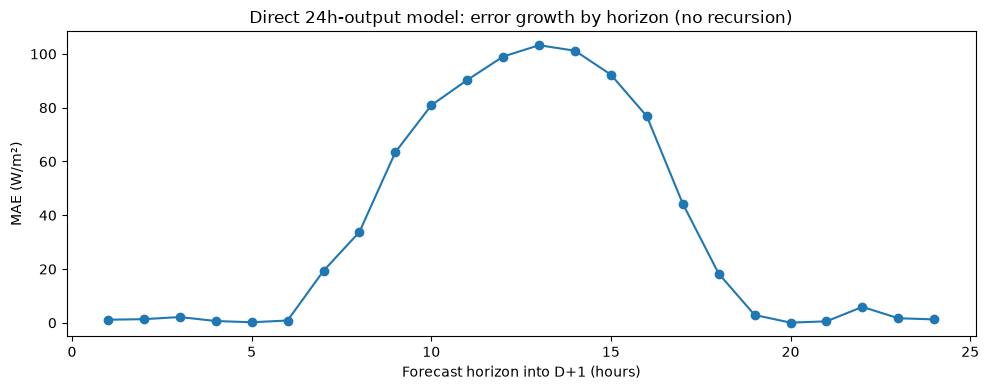

In [17]:
plt.figure(figsize=(10, 4))
plt.plot(horizon_df['horizon_h'], horizon_df['mae'], marker='o')
plt.xlabel('Forecast horizon into D+1 (hours)')
plt.ylabel('MAE (W/m²)')
plt.title('Direct 24h-output model: error growth by horizon (no recursion)')
plt.tight_layout(); plt.show()


In [18]:
# per-state breakdown, so the pooled number isn't hiding a bad state
state_of_origin = np.array([m[0] for m in origin_meta])
per_state_rows = []
for state in sorted(set(state_of_origin)):
    mask = state_of_origin == state
    yt = y_true_next_day[mask].flatten()
    yp = y_pred_next_day[mask].flatten()
    per_state_rows.append({
        'state': state, 'n_origins': int(mask.sum()),
        'mae': mean_absolute_error(yt, yp),
        'rmse': np.sqrt(mean_squared_error(yt, yp)),
        'r2': r2_score(yt, yp),
    })
per_state_df = pd.DataFrame(per_state_rows)
per_state_df


,state,n_origins,mae,rmse,r2
0,Johor (Johor Bahru),729,41.398022,82.293002,0.900354
1,Kedah (Alor Setar),729,34.480209,67.644962,0.940234
2,Kelantan (Kota Bharu),729,38.093685,76.510607,0.929776
3,Kuala Lumpur,729,31.151691,62.101558,0.944414
4,Melaka (Bandar Melaka),729,33.120434,65.776006,0.937727
5,Negeri Sembilan (Seremban),729,36.888973,72.057577,0.933371
6,Pahang (Kuantan),729,37.270351,74.790564,0.927465
7,Penang (George Town),729,34.781170,67.438293,0.943607
8,Perak (Ipoh),729,30.561432,58.907640,0.951953
9,Perlis (Kangar),729,34.447395,67.031997,0.941313


In [19]:
horizon_df.to_csv(f'rolling_origin_direct_by_horizon_{RUN_NAME}.csv', index=False)
per_state_df.to_csv(f'rolling_origin_direct_by_state_{RUN_NAME}.csv', index=False)
print(f'saved rolling_origin_direct_by_horizon_{RUN_NAME}.csv, rolling_origin_direct_by_state_{RUN_NAME}.csv')


saved rolling_origin_direct_by_horizon_d_raw.csv, rolling_origin_direct_by_state_d_raw.csv


## 10. Save run summary (for cross-run comparison)

Every config in the sweep writes one JSON here with its config + key metrics
(`validation_pooled` -- the selection metric, plus `test_pooled`/
`rollout_pooled` for completeness), so the six runs can be collected into
one comparison table afterward without re-parsing each executed notebook's
cell outputs. See `collect_sweep_results.py`, which ranks by
`validation_pooled.rmse`.


In [20]:
summary = {
    'run_name': RUN_NAME,
    # the metric to use for picking the sweep winner (RMSE primary, MAE/R2 supporting) --
    # test_pooled/rollout_pooled below are recorded for completeness only, not for selection
    'validation_pooled': {'mae': float(val_mae), 'rmse': float(val_rmse), 'r2': float(val_r2), 'mbe': val_mbe, 'nrmse': val_nrmse},
    'config': {
        'lstm1_units': LSTM1_UNITS,
        'lstm2_units': LSTM2_UNITS,
        'dropout_rate': DROPOUT_RATE,
        'dense_units': DENSE_UNITS,
        'learning_rate': LEARNING_RATE,
        'batch_size': BATCH_SIZE,
        'recurrent_dropout_rate': RECURRENT_DROPOUT_RATE,
    },
    'total_params': int(model.count_params()),
    'best_epoch': best_epoch,
    'epochs_trained': len(history.history['val_loss']),
    'train_duration_min': train_duration_sec / 60,
    'test_pooled': {'mae': float(mae), 'rmse': float(rmse), 'r2': float(r2), 'mbe': mbe, 'nrmse': nrmse},
    'test_persistence_baseline': {'mae': float(baseline_mae), 'rmse': float(baseline_rmse)},
    'rollout_pooled': {
        'mae': float(rollout_mae),
        'rmse': float(rollout_rmse),
        'r2': float(rollout_r2),
        'mbe': rollout_mbe,
        'nrmse': rollout_nrmse,
    },
}

import json
with open(f'summary_{RUN_NAME}.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))


{
  "run_name": "d_raw",
  "validation_pooled": {
    "mae": 33.0943603515625,
    "rmse": 65.51329033820161,
    "r2": 0.9428206086158752,
    "mbe": 0.3900231719017029,
    "nrmse": 32.337641391572916
  },
  "config": {
    "lstm1_units": 128,
    "lstm2_units": 64,
    "dropout_rate": 0.2,
    "dense_units": 16,
    "learning_rate": 0.001,
    "batch_size": 128,
    "recurrent_dropout_rate": 0.0
  },
  "total_params": 124072,
  "best_epoch": 17,
  "epochs_trained": 22,
  "train_duration_min": 41.709587355454765,
  "test_pooled": {
    "mae": 33.883628845214844,
    "rmse": 67.12572014278506,
    "r2": 0.9401534199714661,
    "mbe": 0.2750553488731384,
    "nrmse": 33.05878373616015
  },
  "test_persistence_baseline": {
    "mae": 43.70606955970164,
    "rmse": 94.16540844641622
  },
  "rollout_pooled": {
    "mae": 35.07125473022461,
    "rmse": 69.56138742933288,
    "r2": 0.9357247352600098,
    "mbe": 1.6547424793243408,
    "nrmse": 34.26001581170415
  }
}
